# To look at statistical 

In [ ]:
import os
import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import glob, io, re
import numpy as np, rasterio
from rasterio import features
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin
import matplotlib.pyplot as plt
from PIL import Image

import datetime as dt
import matplotlib, matplotlib.colors
from pyproj import Transformer
from rasterio.windows import Window


import glob
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
from shapely.geometry import box

In [2]:
# folder = "web_data"
# nvdi_data = folder + "/ndvi"
# fire_data = folder + "/fire"

# NDVI = []
# FIRE = []

# for v, item in enumerate(os.listdir(path=nvdi_data)):
#     # item
#     pathname = str(item)
#     if "manifest" not in pathname:
#         NDVI.append(pathname)
#         # print(len(NDVI), item)

# for v, item in enumerate(os.listdir(path=fire_data)):
#     # item
#     pathname = str(item)
#     if "manifest" not in pathname:
#         FIRE.append(pathname)
#         # print(len(FIRE), item)

In [3]:
CRS = "ESRI:102008"
CELL_SIZE = 50_000  # cell size in meters

land = gpd.read_file("../site/public/geo_files/NA.geojson").to_crs(CRS)
minx, miny, maxx, maxy = land.total_bounds

cells = [box(x, y, x + CELL_SIZE, y + CELL_SIZE)
         for x in np.arange(minx, maxx, CELL_SIZE)
         for y in np.arange(miny, maxy, CELL_SIZE)]
grid = gpd.GeoDataFrame(geometry=cells, crs=CRS)
grid = grid[grid.intersects(land.unary_union)].reset_index(drop=True)
grid["cell_id"] = grid.index
print(len(grid), "cells")

C:\Users\trist\AppData\Local\Temp\ipykernel_58740\1793400665.py:11: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  grid = grid[grid.intersects(land.unary_union)].reset_index(drop=True)


10040 cells


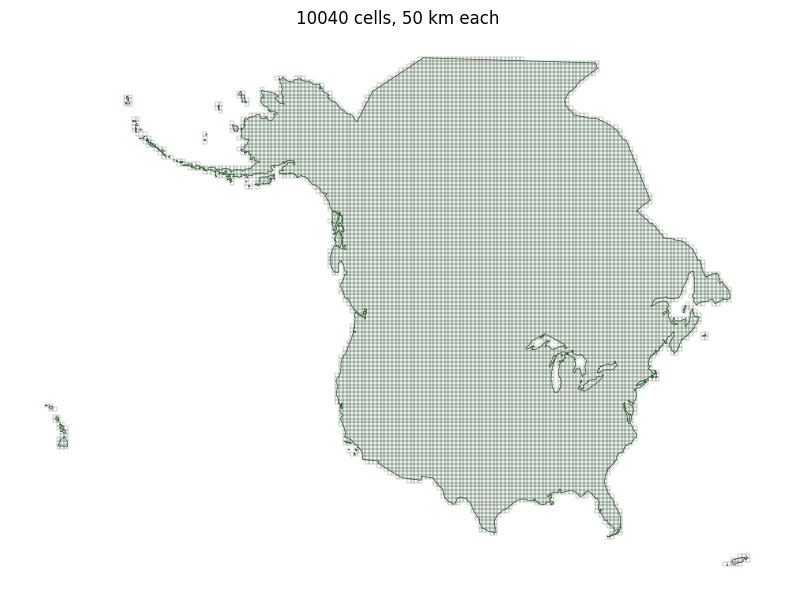

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))
land.plot(ax=ax, color="#e8f5e9", edgecolor="#1b5e20", linewidth=0.5)
grid.plot(ax=ax, facecolor="none", edgecolor="#555", linewidth=0.2)
ax.set_title(f"{len(grid)} cells, {CELL_SIZE/1000:.0f} km each")
ax.set_axis_off()
plt.show()

In [4]:
# raster grid that lines up with the 50 km cells
W = int(np.ceil((maxx - minx) / CELL_SIZE))
H = int(np.ceil((maxy - miny) / CELL_SIZE))
top = miny + H * CELL_SIZE
dst_transform = from_origin(minx, top, CELL_SIZE, CELL_SIZE)
extent = [minx, minx + W * CELL_SIZE, miny, top]

# land mask (so ocean stays blank)
land_mask = features.rasterize(
    [(g, 1) for g in land.geometry],
    out_shape=(H, W), transform=dst_transform, fill=0, all_touched=True,
).astype(bool)

def aggregate(path):
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float32")
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
        arr[arr < -2000] = np.nan                  # MODIS fill / invalid
        if np.nanmax(arr) > 2:
            arr /= 10000                           # MODIS scale factor
        out = np.full((H, W), np.nan, dtype="float32")
        reproject(
            arr, out,
            src_transform=src.transform, src_crs=src.crs, src_nodata=np.nan,
            dst_transform=dst_transform, dst_crs=CRS, dst_nodata=np.nan,
            resampling=Resampling.average,
        )
    out[~land_mask] = np.nan
    return out



In [5]:
files = sorted(glob.glob("web_data/ndvi/*.tif"))
print(files)   # you mentioned 8 months but listed 7: check what's here

stack = {}
for f in files:
    month = int(re.search(r"ndvi_2026_(\d\d)", f).group(1))
    stack[month] = aggregate(f)
    print(month, "mean NDVI:", np.nanmean(stack[month]).round(3))

# build the GIF
cmap = plt.get_cmap("YlGn").copy()
cmap.set_bad("white")
frames = []
for month, a in stack.items():
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(a, extent=extent, cmap=cmap, vmin=0, vmax=1)
    ax.set_title(f"Mean NDVI per 50 km cell, 2026-{month:02d}")
    ax.set_axis_off()
    fig.colorbar(im, ax=ax, shrink=0.7, label="NDVI")
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=100, facecolor="white")
    plt.close(fig)
    frames.append(Image.open(buf).convert("RGB"))

frames[0].save("ndvi_timelapse.gif", save_all=True,
               append_images=frames[1:], duration=900, loop=0)
print("saved ndvi_timelapse.gif")

['web_data/ndvi\\ndvi_2026_04.tif', 'web_data/ndvi\\ndvi_2026_05.tif', 'web_data/ndvi\\ndvi_2026_06.tif', 'web_data/ndvi\\ndvi_2026_07.tif', 'web_data/ndvi\\ndvi_2026_08.tif', 'web_data/ndvi\\ndvi_2026_09.tif', 'web_data/ndvi\\ndvi_2026_10.tif']
4 mean NDVI: 0.264
5 mean NDVI: 0.419
6 mean NDVI: 0.558
7 mean NDVI: 0.61
8 mean NDVI: 0.603
9 mean NDVI: 0.559
10 mean NDVI: 0.441
saved ndvi_timelapse.gif


In [ ]:

def burn_points(path, strip=2048):
    """Return (row, col, day_of_year) in the 50 km grid for every burned pixel."""
    R, C, D = [], [], []
    with rasterio.open(path) as src:
        tf = Transformer.from_crs(src.crs, CRS, always_xy=True)
        for r0 in range(0, src.height, strip):
            win = Window(0, r0, src.width, min(strip, src.height - r0))
            a = src.read(1, window=win)
            r, c = np.nonzero(a > 0)              # 0 = unburned, -1/-2 = unmapped/water
            if r.size == 0:
                continue
            xs, ys = rasterio.transform.xy(src.window_transform(win), r, c)
            X, Y = tf.transform(np.asarray(xs), np.asarray(ys))
            ci = np.floor((X - minx) / CELL_SIZE).astype(int)
            ri = np.floor((top - Y) / CELL_SIZE).astype(int)
            ok = (ci >= 0) & (ci < W) & (ri >= 0) & (ri < H)
            R.append(ri[ok]); C.append(ci[ok]); D.append(a[r, c][ok])
    return np.concatenate(R), np.concatenate(C), np.concatenate(D)

218,832 burned pixels across 2 files
saved burn_timelapse.gif, 9 frames


In [8]:
files = sorted(glob.glob("web_data/fire/*.tif"))
months = [int(re.search(r"Burn_Date_2026(\d\d)01", f).group(1)) for f in files]

# one count grid per month: burned 500 m pixels per 50 km cell
monthly = {}
for f, m in zip(files, months):
    ri, ci, _ = burn_points(f)
    monthly[m] = np.bincount(ri * W + ci, minlength=H * W).reshape(H, W).astype("float32")
    print(f"month {m:02d}: {int(monthly[m].sum()):,} burned pixels, "
          f"{int((monthly[m] > 0).sum()):,} cells with any burn, max {int(monthly[m].max())}")

# one color scale shared by every frame, so months are comparable
vmax = max(max(a.max() for a in monthly.values()), 10)
norm = matplotlib.colors.LogNorm(vmin=1, vmax=vmax)
land_cmap = matplotlib.colors.ListedColormap(["#0e0e12", "#2a2a33"])
fire_cmap = plt.get_cmap("inferno")

frames = []
for m in sorted(monthly):
    shown = np.ma.masked_less_equal(monthly[m], 0)   # unburned land stays dark
    fig, ax = plt.subplots(figsize=(10, 8), facecolor="#0e0e12")
    ax.imshow(land_mask.astype(int), extent=extent, cmap=land_cmap, vmin=0, vmax=1)
    im = ax.imshow(shown, extent=extent, cmap=fire_cmap, norm=norm)
    ax.set_title(f"Burned 500 m pixels per 50 km cell, {dt.date(2026, m, 1):%B %Y}",
                 color="white")
    ax.set_axis_off()
    cb = fig.colorbar(im, ax=ax, shrink=0.7)
    cb.set_label("Burned pixels per cell (log scale)", color="white")
    cb.ax.yaxis.set_tick_params(color="white")
    plt.setp(cb.ax.get_yticklabels(), color="white")
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=100, facecolor=fig.get_facecolor())
    plt.close(fig)
    frames.append(Image.open(buf).convert("RGB"))

frames[0].save("burn_timelapse.gif", save_all=True, append_images=frames[1:], duration=2000, loop=0)
print("saved burn_timelapse.gif,", len(frames), "frames")

month 07: 164,435 burned pixels, 533 cells with any burn, max 9234
month 08: 54,397 burned pixels, 250 cells with any burn, max 2519
saved burn_timelapse.gif, 2 frames
